## TITANIC

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_original=pd.read_csv('titanic.csv')

In [3]:
df=df_original.copy()

In [4]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.shape

(891, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [7]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


OBSERVATIONS:
- 38.4% is the survival rate
- Age ranges from 4 months to 80 yrs and avg age is 30 yrs
- Fare has outliers where avg is 32.2 and max is 512


<Axes: xlabel='Age'>

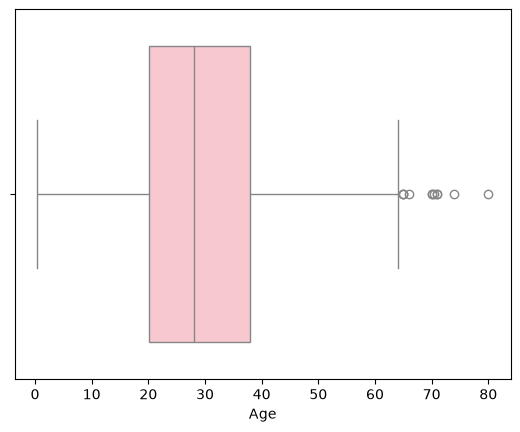

In [8]:
# age distribution before mean imputation
sns.boxplot(data=df,x='Age',color='pink')

In [9]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teen', 'Young Adult', 'Adult', 'Senior']
)

print(df.groupby('AgeGroup', observed=True)['Survived'].agg(
    Survival_Rate='mean',
    Passenger_Count='count'
))

             Survival_Rate  Passenger_Count
AgeGroup                                   
Child             0.579710               69
Teen              0.428571               70
Young Adult       0.382682              358
Adult             0.400000              195
Senior            0.227273               22


In [10]:
df['Age'].mean()

29.69911764705882

In [11]:
# DATA CLEANING

In [12]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
AgeGroup       177
dtype: int64

In [13]:
df.duplicated().sum()

0

In [14]:
# filling embarked missing values

df['Embarked'].value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

In [15]:
df[df['Embarked'].isnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,AgeGroup
61,62,1,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN,Adult
829,830,1,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN,Senior


In [16]:
print(df['Embarked'].mode()[0])

S


In [17]:
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0])

In [18]:
# filling missing cabin values

df['Has_Cabin']=df['Cabin'].notnull().astype(int)

In [19]:
df['Has_Cabin'].value_counts()

Has_Cabin
0    687
1    204
Name: count, dtype: int64

In [20]:
# dropping original cabin column 

# df.drop('Cabin',axis=1,inplace=True)

For missing values of AGE , there are 4 methods to deal with it :
1. mean imputation
2. median imputation
3. groupwise median imputation
4. knn imputation
5. model based imputation

In [21]:
print(df['Age'].mean())

29.69911764705882


In [22]:
# METHOD 1 mean imputation
df['Age']=df['Age'].fillna(df['Age'].mean())

In [23]:
# UNIVARIATE ANALYSIS

Analysing categorical columns


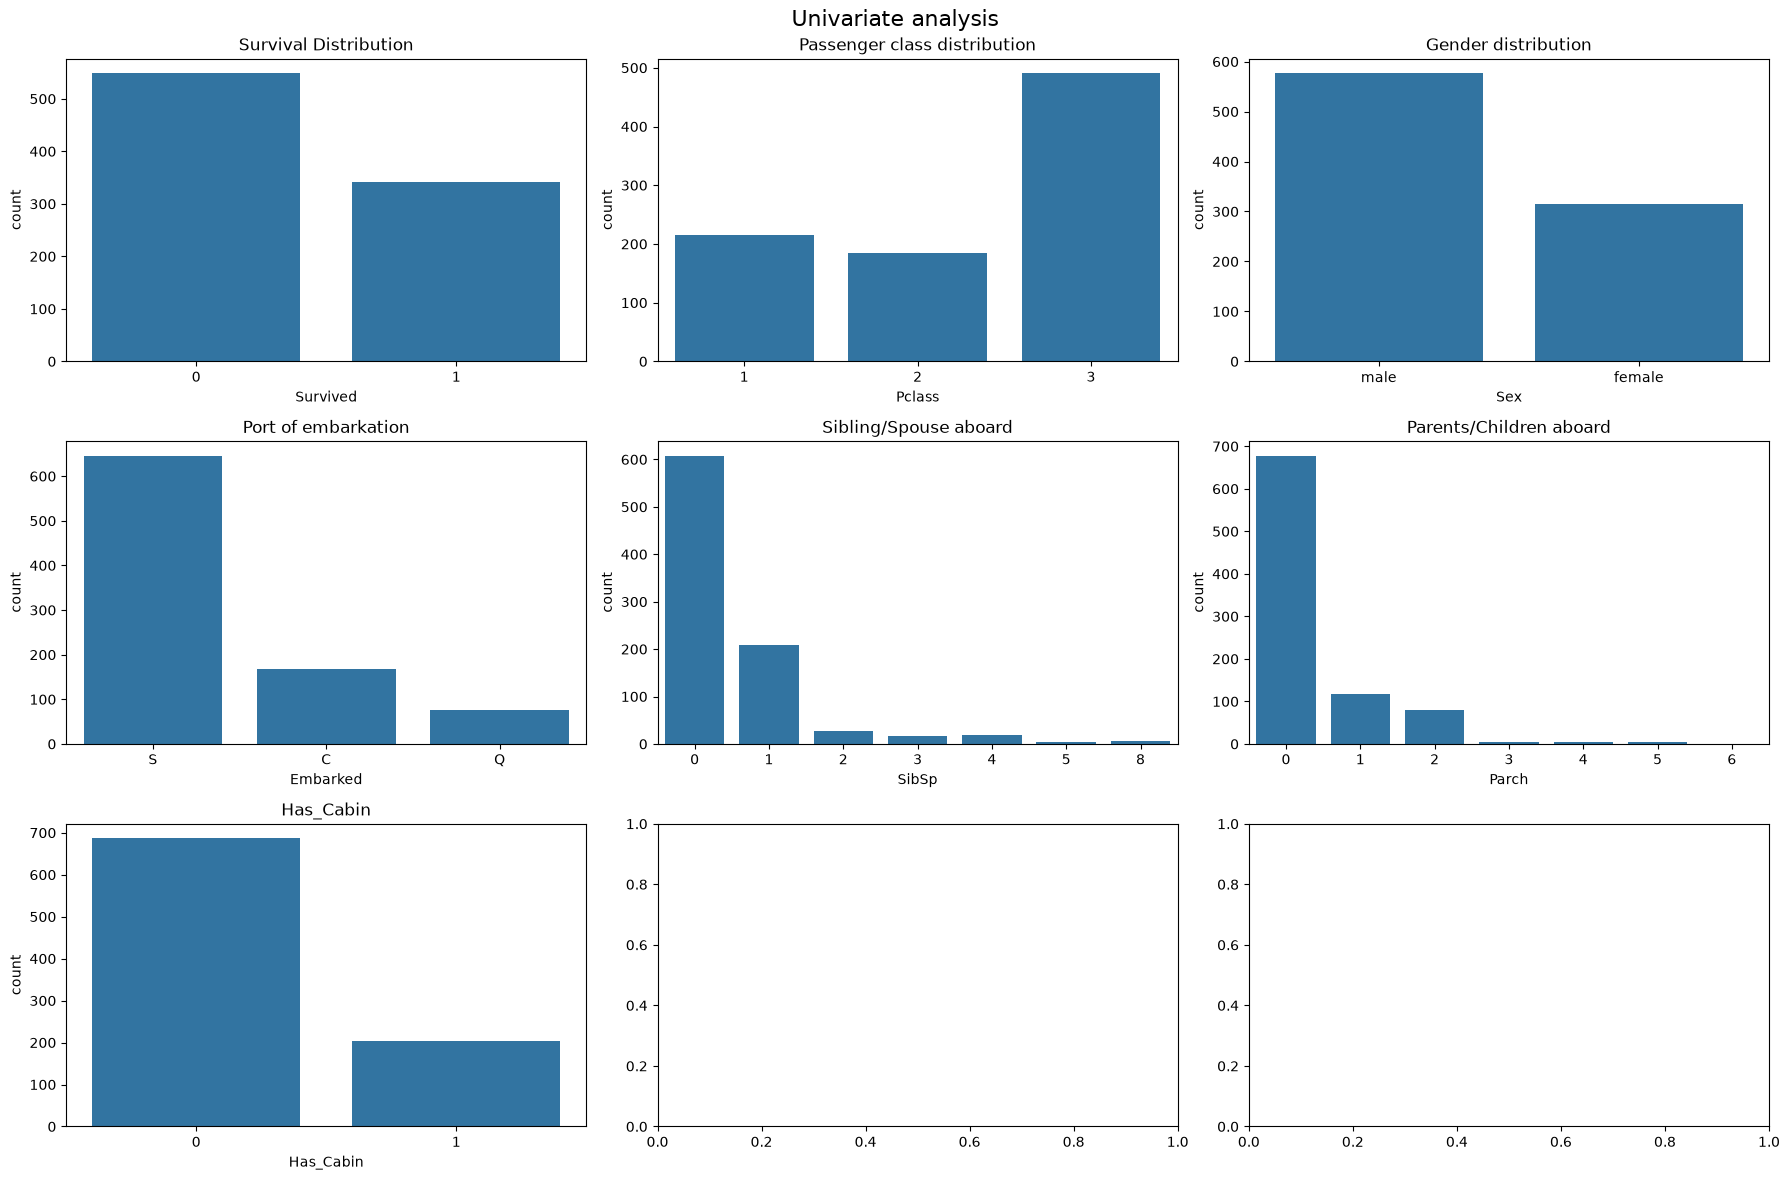

In [24]:
print('Analysing categorical columns')

# set up the fig. for plotting 
fig,axes=plt.subplots(3,3,figsize=(18,12))
fig.suptitle('Univariate analysis',fontsize=16)

# plotting each categorical feature
sns.countplot(ax=axes[0,0],x='Survived',data=df).set_title('Survival Distribution')
sns.countplot(ax=axes[0,1],x='Pclass',data=df).set_title('Passenger class distribution')
sns.countplot(ax=axes[0,2],x='Sex',data=df).set_title('Gender distribution')
sns.countplot(ax=axes[1,0],x='Embarked',data=df).set_title('Port of embarkation')
sns.countplot(ax=axes[1,1],x='SibSp',data=df).set_title('Sibling/Spouse aboard')
sns.countplot(ax=axes[1,2],x='Parch',data=df).set_title('Parents/Children aboard')
sns.countplot(ax=axes[2,0],x='Has_Cabin',data=df).set_title('Has_Cabin')

plt.tight_layout(rect=[0,0,1,1])
plt.show()

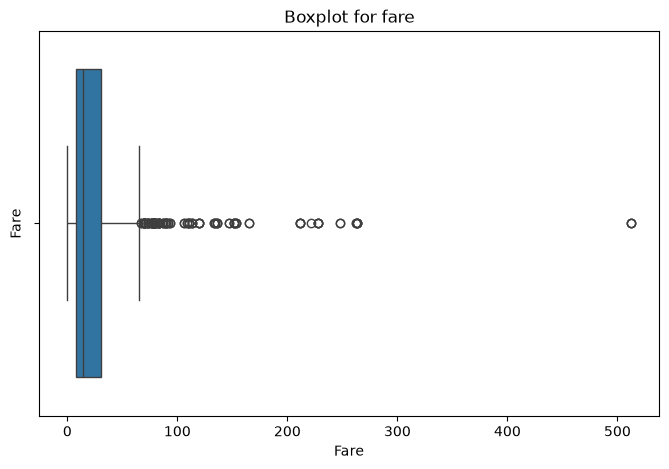

In [25]:
# Boxplot for fare

plt.figure(figsize=(8,5))
sns.boxplot(data=df,x='Fare')
plt.title('Boxplot for fare')
plt.ylabel('Fare')
plt.show()

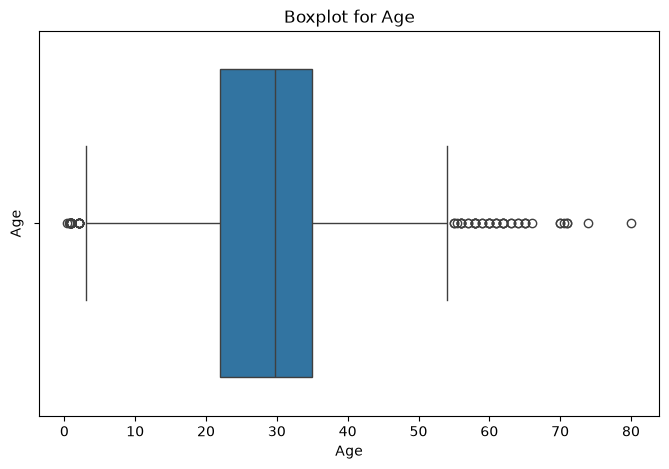

In [26]:
# boxplot for age
plt.figure(figsize=(8,5))
sns.boxplot(data=df,x='Age')
plt.title('Boxplot for Age')
plt.ylabel('Age')
plt.show()

In [27]:
print(df[['Fare', 'Age']].skew())

Fare    4.787317
Age     0.434488
dtype: float64


Analysing numerical columns


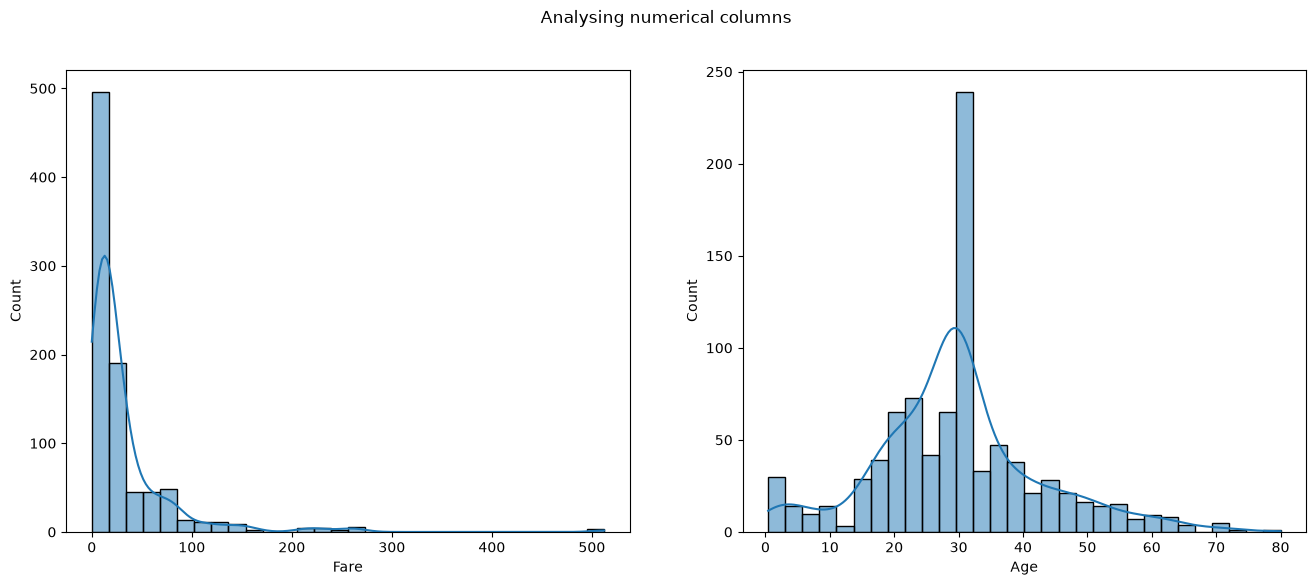

In [28]:
# Analysing numerical columns 
print('Analysing numerical columns')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Analysing numerical columns')

sns.histplot(ax=axes[0],data=df,x='Fare',kde=True,bins=30)
sns.histplot(ax=axes[1],data=df,x='Age',kde=True,bins=30)

plt.show()

In [29]:
df['Deck']=df['Cabin'].str[0]

In [30]:
df['Deck'].value_counts()

Deck
C    59
B    47
D    33
E    32
A    15
F    13
G     4
T     1
Name: count, dtype: int64

OBSERVATIONS :
- Most passengers belong to the 20-30 age range. Imputing the missing values with mean value contributes to the height of that central bar.
- Most tickets were under 50 pounds, with a few very expensive exception


In [31]:
# BIVARIATE ANALYSIS
# 1. cat vs cat
# 2. num vs num
# 3. cat vs num

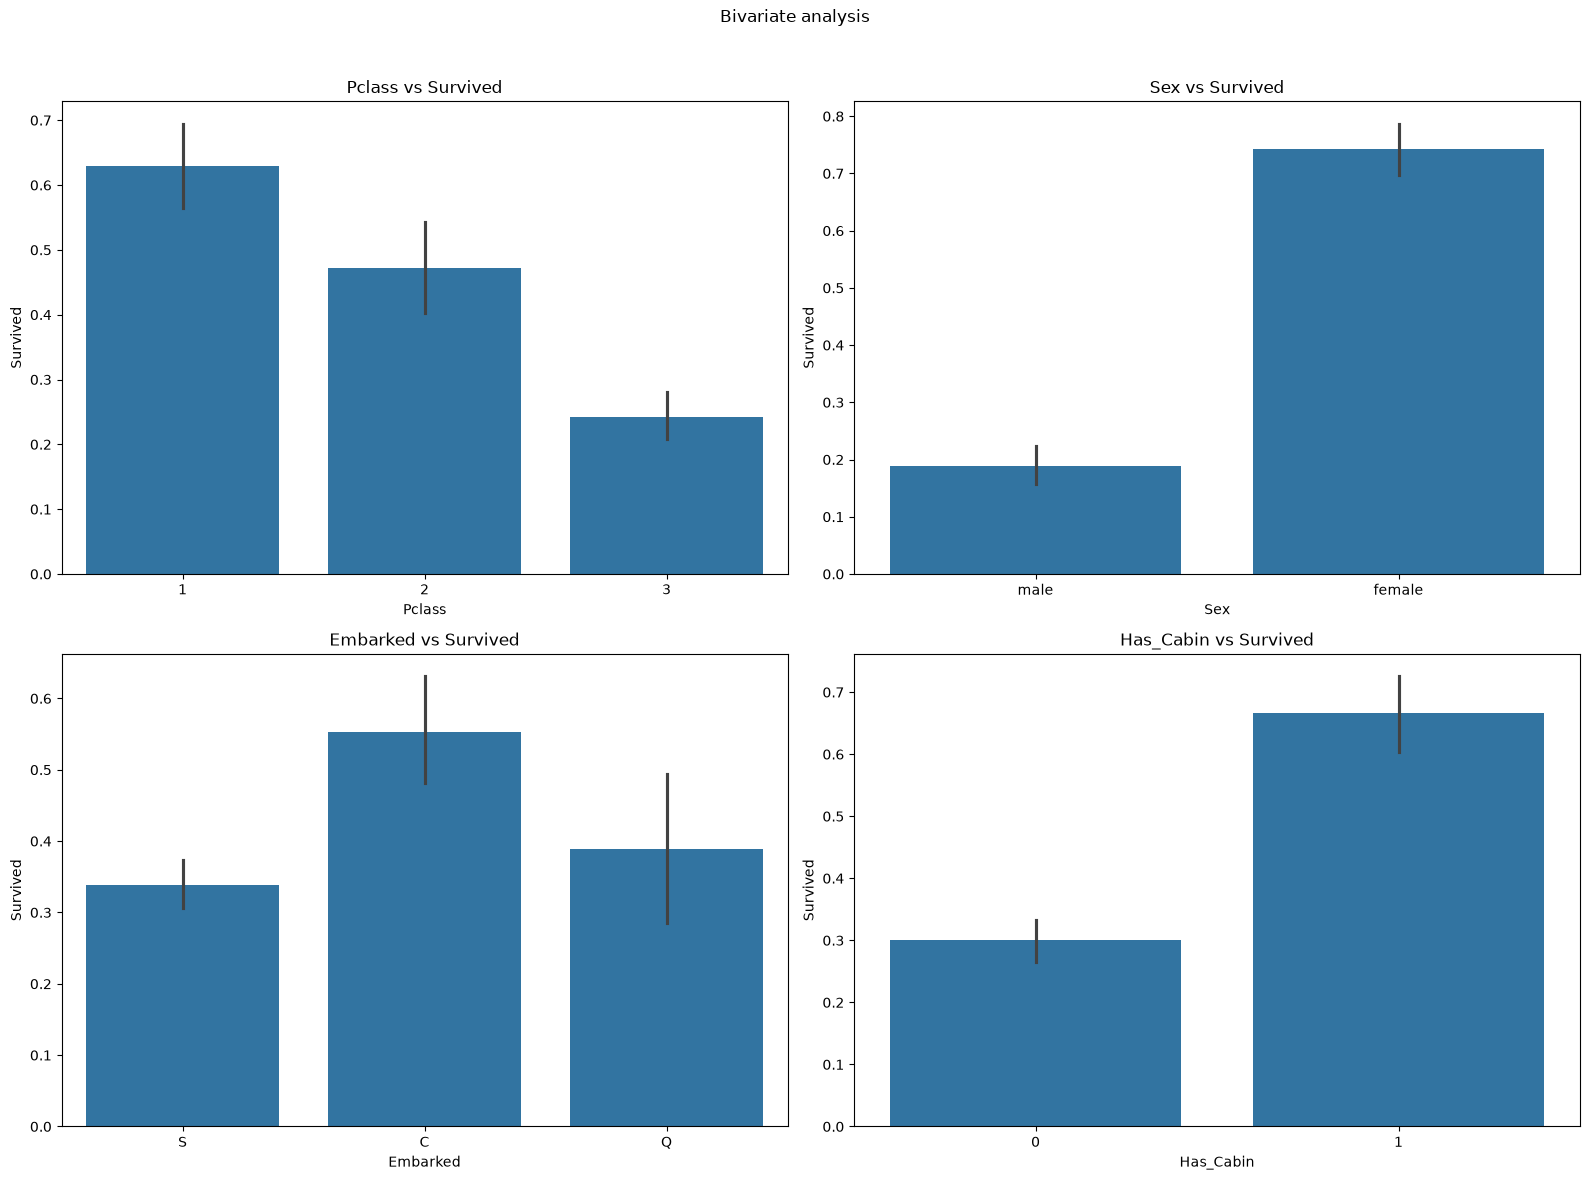

In [32]:
# bivariate analysis : cat vs survival

fig,axes=plt.subplots(2,2,figsize=(16,12))
fig.suptitle('Bivariate analysis')

# pclass vs survived
sns.barplot(ax=axes[0,0],data=df,x='Pclass',y='Survived').set_title('Pclass vs Survived')

# gender vs survived
sns.barplot(ax=axes[0,1],data=df,x='Sex',y='Survived').set_title('Sex vs Survived')

# embarked vs survived
sns.barplot(ax=axes[1,0],data=df,x='Embarked',y='Survived').set_title('Embarked vs Survived')

# has_cabin vs survived
sns.barplot(ax=axes[1,1],data=df,x='Has_Cabin',y='Survived').set_title('Has_Cabin vs Survived')

plt.tight_layout(rect=[0,0,1,0.96])
plt.show()

In [33]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'AgeGroup', 'Has_Cabin',
       'Deck'],
      dtype='object')

<Axes: xlabel='SibSp', ylabel='Survived'>

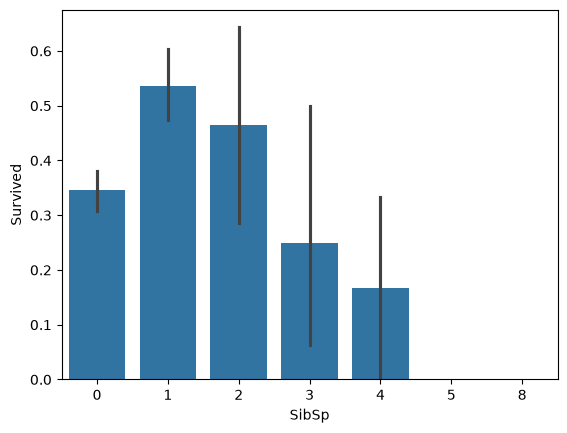

In [34]:
# SibSp vs survived
sns.barplot(data=df,x='SibSp',y='Survived')

<Axes: xlabel='Parch', ylabel='Survived'>

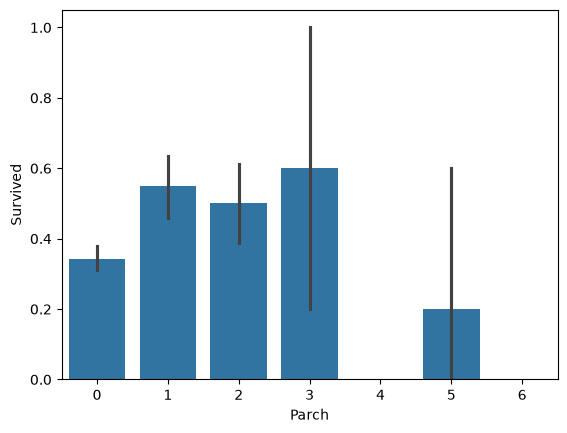

In [35]:
# Parch vs survived
sns.barplot(data=df,x='Parch',y='Survived')

In [36]:
df['TicketGroupSize'] = df.groupby('Ticket')['Ticket'].transform('count')

print(
    df.groupby('TicketGroupSize', observed=True)['Survived']
      .agg(['count', 'mean'])
)

                 count      mean
TicketGroupSize                 
1                  547  0.297989
2                  188  0.574468
3                   63  0.698413
4                   44  0.500000
5                   10  0.000000
6                   18  0.000000
7                   21  0.238095


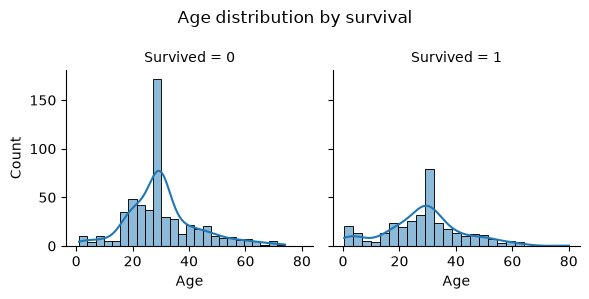

In [37]:
# Age vs Survival 
g=sns.FacetGrid(data=df,col='Survived')
g.map(sns.histplot,'Age',kde=True,bins=25)
plt.suptitle('Age distribution by survival')
plt.tight_layout(rect=[0,0,1,1])
plt.show()

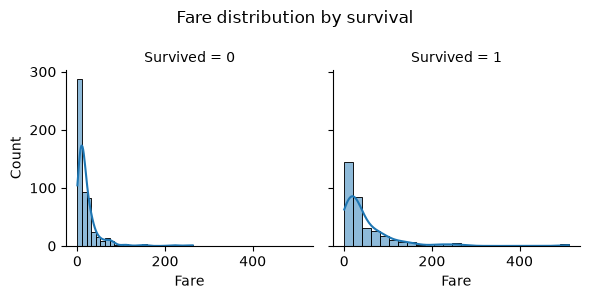

In [38]:
# Fare vs survival 
g=sns.FacetGrid(data=df,col='Survived')
g.map(sns.histplot,'Fare',kde=True,bins=25)
plt.suptitle('Fare distribution by survival')
plt.tight_layout(rect=[0,0,1,1])
plt.show()

In [39]:
df['FareGroup'] = pd.qcut(df['Fare'], q=4, duplicates='drop')
print(df.groupby('FareGroup', observed=True)['Survived'].mean())

FareGroup
(-0.001, 7.91]     0.197309
(7.91, 14.454]     0.303571
(14.454, 31.0]     0.454955
(31.0, 512.329]    0.581081
Name: Survived, dtype: float64


In [40]:
print(df.groupby('Pclass')['Survived'].mean())

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


OBSERVATIONS:
- Survival rates are highest among 1st class passengers (over 60%) , 2nd class 47.3% and 3rd class 24.2%.
- Abt 75% females survived , compared to <20% males.
- Passengers who boarded at Cherbourg C experienced higher survival rates than those from other ports.
- Having a recorded cabin number was associated with a much greater chance of survival.
- Infants and young children were more likely to survive.
- Most non survivors were young adults (ages 20-40).
- None of the oldest passengers (age 80) survived.
- Higher fares and higher passenger class are associated with better survival outcomes in this dataset.
  

In [41]:
# FEATURE ENGINEERING 

In [42]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'AgeGroup', 'Has_Cabin',
       'Deck', 'TicketGroupSize', 'FareGroup'],
      dtype='object')

In [43]:
# combining sibsp+parch

df['Family_size']=df['SibSp']+df['Parch']+1

In [44]:
df['IsAlone']=(df['Family_size']==1).astype(int)

In [45]:
df[['Family_size','IsAlone']].head()

,Family_size,IsAlone
0,2,0
1,2,0
2,1,1
3,2,0
4,1,1


In [46]:
# 1 means Alone and 0 means not alone

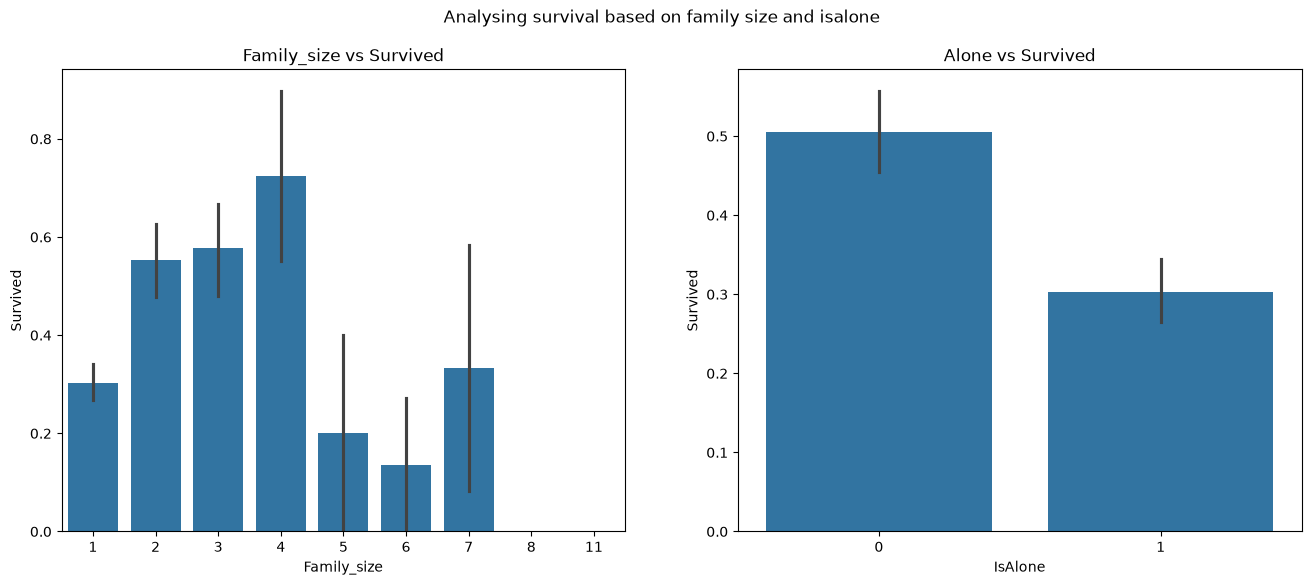

In [47]:
# Analysing family size vs survival

fig,axes=plt.subplots(1,2,figsize=(16,6))
fig.suptitle('Analysing survival based on family size and isalone')

# family_size vs survived
sns.barplot(ax=axes[0],data=df,x='Family_size',y='Survived').set_title('Family_size vs Survived')

# IsAlone vs survived
sns.barplot(ax=axes[1],data=df,x='IsAlone',y='Survived').set_title('Alone vs Survived')

plt.show()

OBSERVATIONS :
- Passengers travelling with small families generally showed higher observed survival rates than passengers travelling alone.
- Larger family groups tended to have lower observed survival rates, although some groups contained relatively few passengers, so those rates should be interpreted cautiously.

In [48]:
# extracting titles from the 'Name' column

df['Title'] = df['Name'].str.extract(r',\s*([^.]*)\.')
df['Title'].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Mlle              2
Major             2
Col               2
the Countess      1
Capt              1
Ms                1
Sir               1
Lady              1
Mme               1
Don               1
Jonkheer          1
Name: count, dtype: int64

In [49]:
# extracting most common titles

common_titles=['Mr','Miss','Mrs','Master']
df['Title']=df['Title'].where(df['Title'].isin(common_titles),'Rare')

In [50]:
df['Title'].value_counts()

Title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

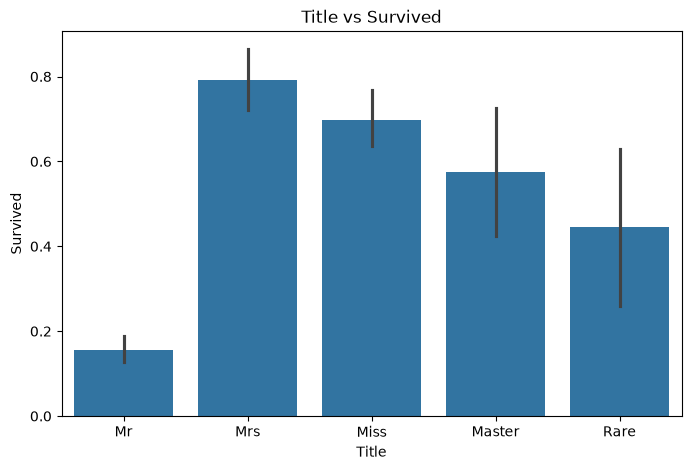

In [51]:
# Analysing title 

plt.figure(figsize=(8,5))
plt.title('Title distribution')

# title vs survived
sns.barplot(data=df,x='Title',y='Survived').set_title('Title vs Survived')

plt.show()

OBSERVATIONS :
- 'Mrs' and 'Miss' (females) had high survival rates.
- 'Mr' (males) had a low survival rate.
- 'Master' (young boys) survived much more than adult men.
- 'Rare' titles (nobility/status) had mixed but survival rate should be interpreted cautiously.

Text(0.5, 1.0, 'Survival rate by Deck')

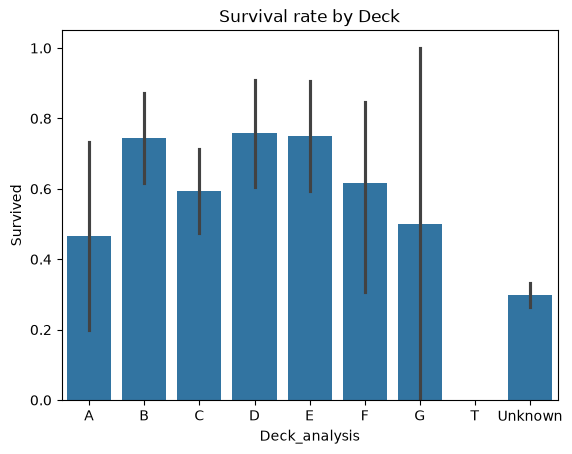

In [52]:
# survival rate by deck
df['Deck_analysis']=df['Deck'].fillna('Unknown')
sns.barplot(data=df,x='Deck_analysis',y='Survived',order=sorted(df['Deck_analysis'].unique()))
plt.title('Survival rate by Deck')

In [53]:
df.groupby('Deck', dropna=False)['Survived'].agg(
    Survival_rate='mean',
    Count='count'
)

,Survival_rate,Count
Deck,,
A,0.466667,15
B,0.744681,47
C,0.593220,59
D,0.757576,33
E,0.750000,32
F,0.615385,13
G,0.500000,4
T,0.000000,1
NaN,0.299854,687


In [54]:
# MULTIVARIATE ANALYSIS

In [55]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'AgeGroup', 'Has_Cabin',
       'Deck', 'TicketGroupSize', 'FareGroup', 'Family_size', 'IsAlone',
       'Title', 'Deck_analysis'],
      dtype='object')

<Figure size 800x500 with 0 Axes>

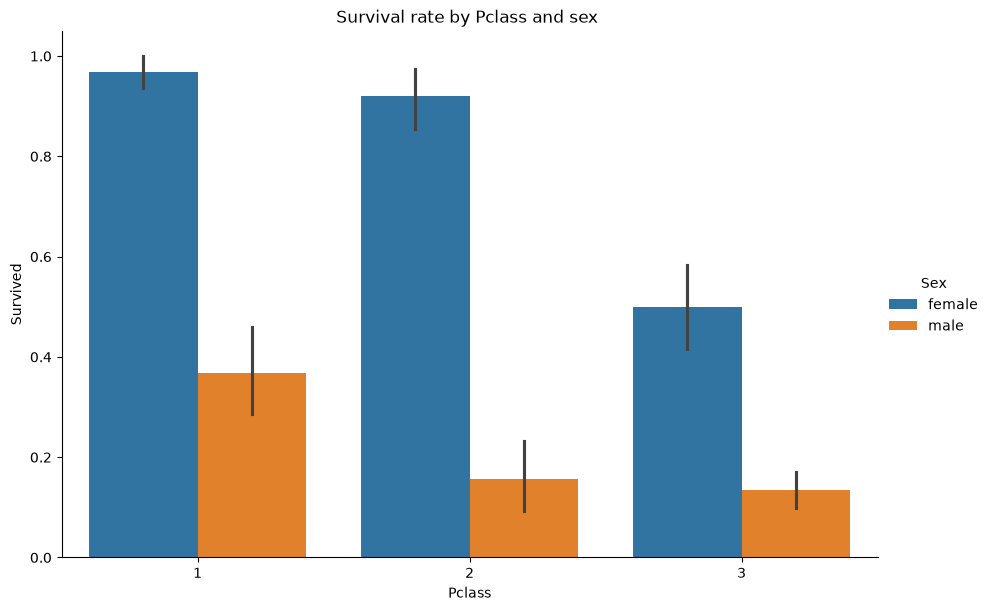

In [56]:
# Survival rate  by Pclass and sex

plt.figure(figsize=(8,5))
sns.catplot(data=df,x='Pclass',y='Survived',hue='Sex',kind='bar',height=6,aspect=1.5)
plt.title('Survival rate by Pclass and sex ')
plt.show()

OBSERVATIONS  :
- Survival rate : 1st class > 2nd class > 3rd class
- Females have higher survival rate than males in all classes

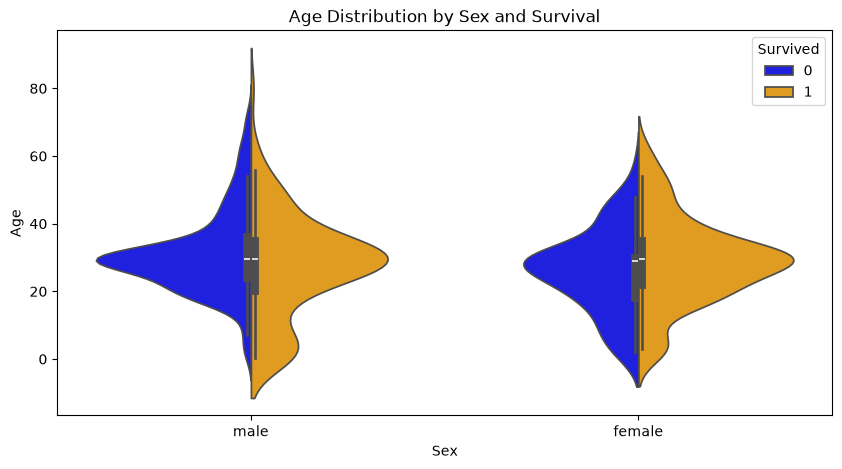

In [57]:
# Violin plot to see age distribution by sex and survival status

plt.figure(figsize=(10, 5))
sns.violinplot(x='Sex', y='Age', hue='Survived', data=df, split=True, palette={0: 'blue', 1: 'orange'})
plt.title('Age Distribution by Sex and Survival')
plt.show()

Observations :
- Male and female age distributions differed between survivors and non-survivors.
- Male children had a higher observed survival rate than males in older age groups.
- Female survival rates were high across several age groups.
- The age-survival relationship appears to differ by sex, but small groups and imputed ages limit interpretation.

In [58]:
# At what age was survival more likely?

In [59]:
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 12, 18, 35, 60, 100],
    labels=['Child', 'Teen', 'Young Adult', 'Adult', 'Senior']
)

print(df.groupby('AgeGroup', observed=True)['Survived'].agg(
    Survival_Rate='mean',
    Passenger_Count='count'
))

             Survival_Rate  Passenger_Count
AgeGroup                                   
Child             0.579710               69
Teen              0.428571               70
Young Adult       0.353271              535
Adult             0.400000              195
Senior            0.227273               22


<Figure size 800x500 with 0 Axes>

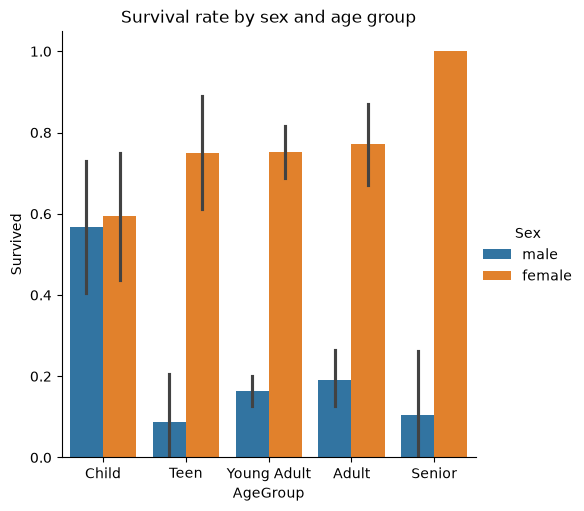

In [60]:
plt.figure(figsize=(8,5))
sns.catplot(data=df,x='AgeGroup',y='Survived',hue='Sex',kind='bar')
plt.title('Survival rate by sex and age group')
plt.show()

In [61]:
print(
    df.groupby(['AgeGroup', 'Sex'], observed=True)
      .agg(
          Passenger_Count=('Survived', 'count'),
          Survivors=('Survived', 'sum'),
          Survival_Rate=('Survived', 'mean')
      )
)

                    Passenger_Count  Survivors  Survival_Rate
AgeGroup    Sex                                              
Child       female               32         19       0.593750
            male                 37         21       0.567568
Teen        female               36         27       0.750000
            male                 34          3       0.088235
Young Adult female              173        130       0.751445
            male                362         59       0.162983
Adult       female               70         54       0.771429
            male                125         24       0.192000
Senior      female                3          3       1.000000
            male                 19          2       0.105263


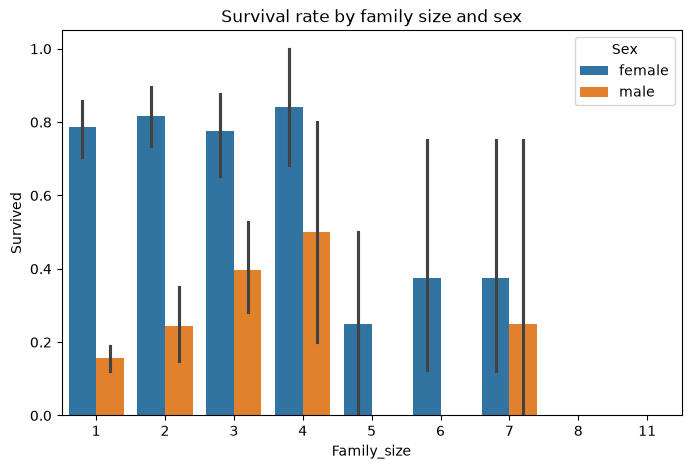

In [62]:
# Analysing survival rate based on family_size and sex 

plt.figure(figsize=(8,5))
plt.title('Survival rate by family size and sex')
sns.barplot(data=df,x='Family_size',y='Survived',hue='Sex')
plt.show()

In [63]:
print(
    df.groupby(['Family_size', 'Sex'], observed=True)
      .agg(
          Passenger_Count=('Survived', 'count'),
          Survivors=('Survived', 'sum'),
          Survival_Rate=('Survived', 'mean')
      )
)

                    Passenger_Count  Survivors  Survival_Rate
Family_size Sex                                              
1           female              126         99       0.785714
            male                411         64       0.155718
2           female               87         71       0.816092
            male                 74         18       0.243243
3           female               49         38       0.775510
            male                 53         21       0.396226
4           female               19         16       0.842105
            male                 10          5       0.500000
5           female               12          3       0.250000
            male                  3          0       0.000000
6           female                8          3       0.375000
            male                 14          0       0.000000
7           female                8          3       0.375000
            male                  4          1       0.250000
8       

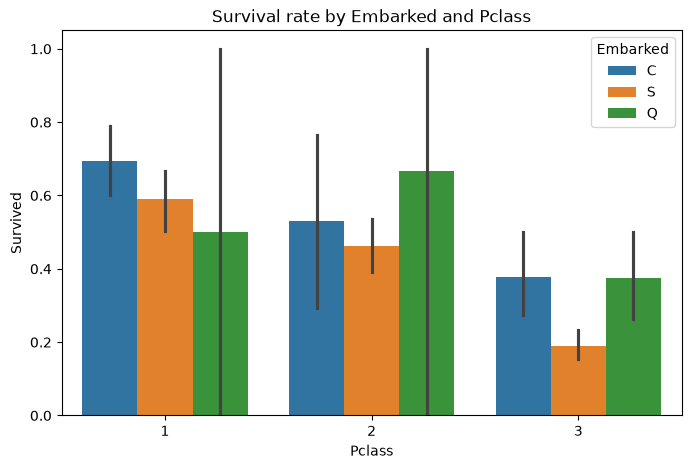

In [64]:
# Analysing survival rate by Embarked and Pclass
plt.figure(figsize=(8,5))
plt.title('Survival rate by Embarked and Pclass')
sns.barplot(data=df,x='Pclass',y='Survived',hue='Embarked')
plt.show()

In [65]:
print(
    df.groupby(['FareGroup', 'Pclass'], observed=True)
      .agg(
          Passenger_Count=('Survived', 'count'),
          Survivors=('Survived', 'sum'),
          Survival_Rate=('Survived', 'mean')
      )
)

                        Passenger_Count  Survivors  Survival_Rate
FareGroup       Pclass                                           
(-0.001, 7.91]  1                     6          0       0.000000
                2                     6          0       0.000000
                3                   211         44       0.208531
(7.91, 14.454]  2                    86         33       0.383721
                3                   138         35       0.253623
(14.454, 31.0]  1                    51         27       0.529412
                2                    70         42       0.600000
                3                   101         32       0.316832
(31.0, 512.329] 1                   159        109       0.685535
                2                    22         12       0.545455
                3                    41          8       0.195122


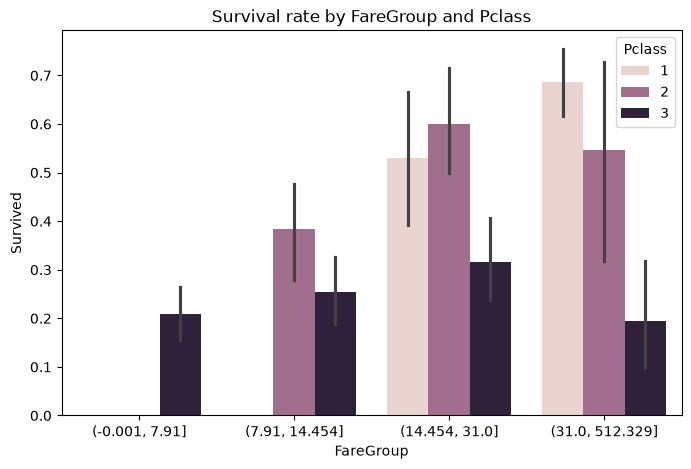

In [66]:
plt.figure(figsize=(8,5))
plt.title('Survival rate by FareGroup and Pclass')
sns.barplot(data=df,x='FareGroup',y='Survived',hue='Pclass')
plt.show()

In [67]:
# CORRELATION MATRIX : basically a heatmap

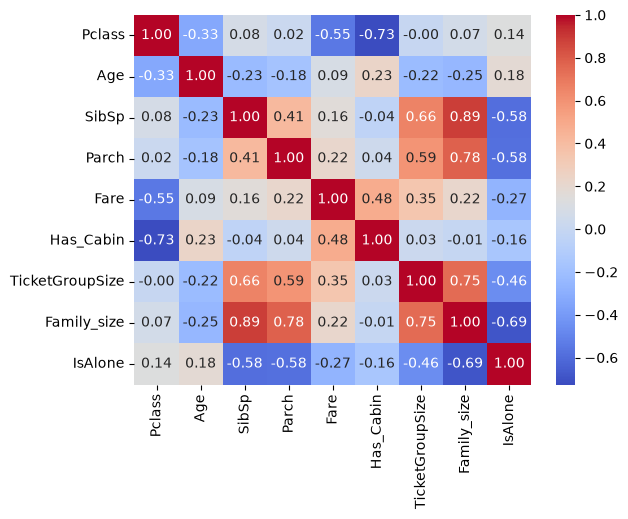

In [68]:
# Correlation Heatmap for numerical features

cols = df.select_dtypes(include='number').drop(
    columns=['PassengerId', 'Survived'],
    errors='ignore'
)

sns.heatmap(cols.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

In [69]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'AgeGroup', 'Has_Cabin',
       'Deck', 'TicketGroupSize', 'FareGroup', 'Family_size', 'IsAlone',
       'Title', 'Deck_analysis'],
      dtype='object')

In [70]:
categorical_cols = [
    'Sex',
    'Pclass',
    'Embarked',
    'Title',
    'Deck',
    'Family_size',
    'IsAlone',
    'TicketGroupSize'
]

for col in categorical_cols:
    print(f'\n{col}')
    print(
        pd.crosstab(
            df[col],
            df['Survived'],
            normalize='index'
        ) * 100
    )


Sex
Survived          0          1
Sex                           
female    25.796178  74.203822
male      81.109185  18.890815

Pclass
Survived          0          1
Pclass                        
1         37.037037  62.962963
2         52.717391  47.282609
3         75.763747  24.236253

Embarked
Survived          0          1
Embarked                      
C         44.642857  55.357143
Q         61.038961  38.961039
S         66.099071  33.900929

Title
Survived          0          1
Title                         
Master    42.500000  57.500000
Miss      30.219780  69.780220
Mr        84.332689  15.667311
Mrs       20.800000  79.200000
Rare      55.555556  44.444444

Deck
Survived           0          1
Deck                           
A          53.333333  46.666667
B          25.531915  74.468085
C          40.677966  59.322034
D          24.242424  75.757576
E          25.000000  75.000000
F          38.461538  61.538462
G          50.000000  50.000000
T         100.000000   0.

In [71]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'AgeGroup', 'Has_Cabin',
       'Deck', 'TicketGroupSize', 'FareGroup', 'Family_size', 'IsAlone',
       'Title', 'Deck_analysis'],
      dtype='object')

## MODELLING - Baseline model

build the first model using a small, sensible set of features.


Pclass,Age,Fare (Numeric)                                                                                                                               
Sex,Embarked,Title (Categorical)

In [72]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'AgeGroup', 'Has_Cabin',
       'Deck', 'TicketGroupSize', 'FareGroup', 'Family_size', 'IsAlone',
       'Title', 'Deck_analysis'],
      dtype='object')

In [73]:
model_df=df.copy()

# whether cabin as recorded cabin
model_df['Cabin']=df['Cabin'].notna().astype(int)

# no. of passengers sharing same ticket
model_df['TicketGroupSize']=(model_df.groupby('Ticket')['Ticket'].transform('count'))

# extracting titles from passenger names
model_df['Title']= model_df['Name'].str.extract(r',\s*([^.]*)\.')

# group uncommon titles into one category
common_titles=['Mr','Mrs','Miss','Master']
model_df['Title']=model_df['Title'].where(model_df['Title'].isin(common_titles),'Rare')


features = [
    'Pclass',
    'Sex',
    'AgeGroup',
    'TicketGroupSize',
    'FareGroup',
    'Family_size',
    'IsAlone',
    'Deck_analysis',
    'Title',
    'Embarked',
    'Has_Cabin'
]

# separating features
X=model_df[features].copy()
y=model_df['Survived']

print("Features:", X.columns.tolist())
print('Features.shape',X.shape)
print('Target.shape',y.shape)

print('Missing values in features')
print(X.isnull().sum())

Features: ['Pclass', 'Sex', 'AgeGroup', 'TicketGroupSize', 'FareGroup', 'Family_size', 'IsAlone', 'Deck_analysis', 'Title', 'Embarked', 'Has_Cabin']
Features.shape (891, 11)
Target.shape (891,)
Missing values in features
Pclass             0
Sex                0
AgeGroup           0
TicketGroupSize    0
FareGroup          0
Family_size        0
IsAlone            0
Deck_analysis      0
Title              0
Embarked           0
Has_Cabin          0
dtype: int64


In [74]:
# splitting the data before imputing and encoding

from sklearn.model_selection import train_test_split
X_train,X_val,y_train,y_val=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print('Training features',X_train.shape)
print('Validation features',X_val.shape)

print('\n Training target')
print(y_train.value_counts(normalize=True))

print('\n Validation target')
print(y_val.value_counts(normalize=True))

Training features (712, 11)
Validation features (179, 11)

 Training target
Survived
0    0.616573
1    0.383427
Name: proportion, dtype: float64

 Validation target
Survived
0    0.614525
1    0.385475
Name: proportion, dtype: float64


In [75]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'AgeGroup', 'Has_Cabin',
       'Deck', 'TicketGroupSize', 'FareGroup', 'Family_size', 'IsAlone',
       'Title', 'Deck_analysis'],
      dtype='object')

In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   PassengerId      891 non-null    int64   
 1   Survived         891 non-null    int64   
 2   Pclass           891 non-null    int64   
 3   Name             891 non-null    object  
 4   Sex              891 non-null    object  
 5   Age              891 non-null    float64 
 6   SibSp            891 non-null    int64   
 7   Parch            891 non-null    int64   
 8   Ticket           891 non-null    object  
 9   Fare             891 non-null    float64 
 10  Cabin            204 non-null    object  
 11  Embarked         891 non-null    object  
 12  AgeGroup         891 non-null    category
 13  Has_Cabin        891 non-null    int32   
 14  Deck             204 non-null    object  
 15  TicketGroupSize  891 non-null    int64   
 16  FareGroup        891 non-null    category
 1

In [77]:
# Creating preprocessing pipeline

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler,PolynomialFeatures
from sklearn.compose import ColumnTransformer

# separate features by data type
numeric_features=['Has_Cabin','TicketGroupSize','Family_size','IsAlone']
categorical_features=['Pclass','Title','Sex','Embarked','AgeGroup','FareGroup']



# pipeline for numeric columns
numeric_transformer=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='median',add_indicator=True)),
    ('scaler',StandardScaler())
])

# pipeline for categorical columns
categorical_transformer=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('encoder',OneHotEncoder(handle_unknown='ignore'))
])

# apply the correct preprocessing to each group of col umns
preprocessor=ColumnTransformer(transformers=[
    ('num',numeric_transformer,numeric_features),
    ('cat',categorical_transformer,categorical_features)
])

In [78]:
print(X_train.columns.tolist()) 

['Pclass', 'Sex', 'AgeGroup', 'TicketGroupSize', 'FareGroup', 'Family_size', 'IsAlone', 'Deck_analysis', 'Title', 'Embarked', 'Has_Cabin']


In [79]:
# join preprocessing and the ML model into one pipeline

#logistic regression
from sklearn.kernel_approximation import RBFSampler
from sklearn.linear_model import LogisticRegression

logistic_num_transformer=Pipeline(steps=[
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler()),
    ('rbf',RBFSampler(gamma=1.0,n_components=100,random_state=42))
])

logistic_preprocessor=ColumnTransformer(transformers=[
    ('num',logistic_num_transformer,numeric_features),
    ('cat',categorical_transformer,categorical_features)
])
model=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('classifier',LogisticRegression(max_iter=1000,class_weight='balanced'))
])

In [80]:
# train the model

model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [81]:
# making predictions on the validation data

y_pred=model.predict(X_val)
print(y_pred[:20])

[0 0 0 0 1 1 1 1 0 0 0 0 1 0 0 0 0 0 0 1]


Validation accuracy 83.2402
              precision    recall  f1-score   support

           0       0.88      0.84      0.86       110
           1       0.76      0.83      0.79        69

    accuracy                           0.83       179
   macro avg       0.82      0.83      0.83       179
weighted avg       0.84      0.83      0.83       179



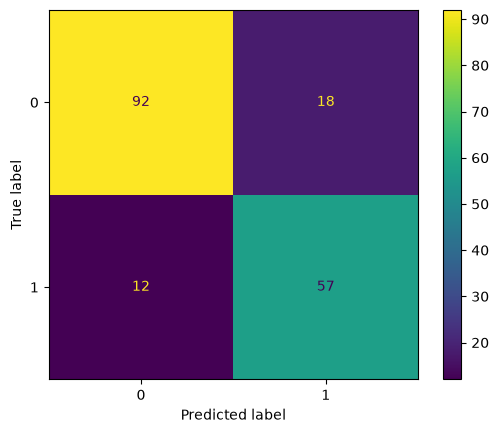

In [82]:
# evaluating your first model 

from sklearn.metrics import (accuracy_score,classification_report,ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

# accuracy
accuracy=accuracy_score(y_val,y_pred)
print('Validation accuracy', round(accuracy*100,4))

# precision,recall and F1 score
print(classification_report(y_val,y_pred))

# confusion matrix
ConfusionMatrixDisplay.from_predictions(y_val,y_pred)
plt.show()

## Using decisiontree classifier and randomforestclassifier

In [83]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [84]:
dt_model=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('decisiontree',DecisionTreeClassifier(random_state=42))
])

rt_model=Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('randomforest',RandomForestClassifier(n_estimators=100,random_state=42))
])

In [85]:
dt_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('decisiontree', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [86]:
rt_model.fit(X_train,y_train)

,steps,"[('preprocessor', ...), ('randomforest', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [87]:
dt_pred=dt_model.predict(X_val)
rt_pred=rt_model.predict(X_val)

Decision tree accuracy 73.743
              precision    recall  f1-score   support

           0       0.77      0.82      0.79       110
           1       0.68      0.61      0.64        69

    accuracy                           0.74       179
   macro avg       0.72      0.71      0.72       179
weighted avg       0.73      0.74      0.73       179



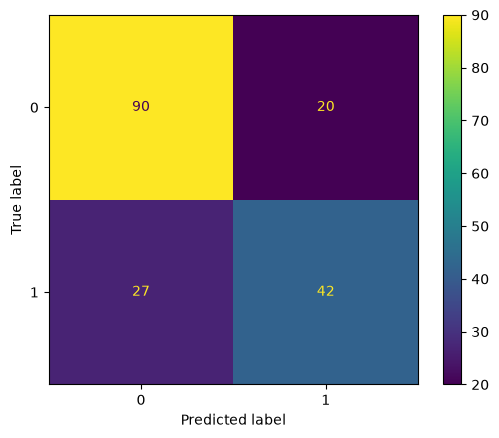

In [88]:
# evaluation for dt_model
dt_accuracy=accuracy_score(y_val,dt_pred)
print('Decision tree accuracy',round(dt_accuracy*100,4))
print(classification_report(y_val,dt_pred))
ConfusionMatrixDisplay.from_predictions(y_val,dt_pred)
plt.show()

Random forest accuracy 77.095
              precision    recall  f1-score   support

           0       0.80      0.84      0.82       110
           1       0.72      0.67      0.69        69

    accuracy                           0.77       179
   macro avg       0.76      0.75      0.75       179
weighted avg       0.77      0.77      0.77       179



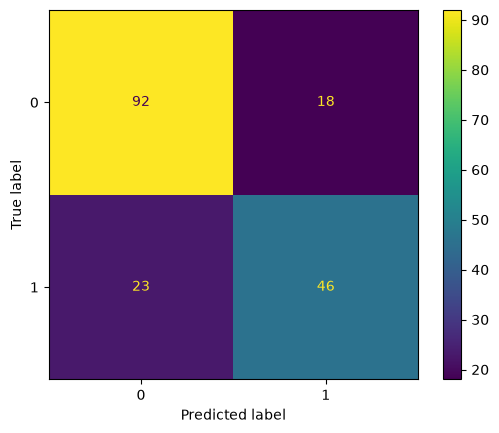

In [89]:
# evaluation for rt_model
rt_accuracy=accuracy_score(y_val,rt_pred)
print('Random forest accuracy',round(rt_accuracy*100,4))
print(classification_report(y_val,rt_pred))
ConfusionMatrixDisplay.from_predictions(y_val,rt_pred)
plt.show()

In [90]:
# COMPARING ALL THREE MODELS 

In [91]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest'
    ],
    'Validation Accuracy': [
        accuracy,
        dt_accuracy,
        rt_accuracy
    ]
})

results['Validation Accuracy'] = (
    results['Validation Accuracy'] * 100
).round(2)

results = results.sort_values(
    by='Validation Accuracy',
    ascending=False
).reset_index(drop=True)

print(results)

                 Model  Validation Accuracy
0  Logistic Regression                83.24
1        Random Forest                77.09
2        Decision Tree                73.74
